In [ ]:
!pip install numpy matplotlib scipy pandas opencv-python -q

import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import cv2
print("Libraries installed and imported successfully.")

Libraries installed and imported successfully.


In [ ]:
import zipfile
import os

zip_file_path = '/content/drive/MyDrive/Harishwar_ICP/Zip_file /train00_timestamped_csv.zip'

output_dir = '/content/scans1/train00_timestamped_csv/'

if not os.path.exists('/content/scans1/'):
    os.makedirs('/content/scans1/')

print(f"Extracting files from {zip_file_path}...")
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall('/content/scans1/')

print(f"Extraction complete. Scans are located in: {output_dir}")
print(f"Found {len(os.listdir(output_dir))} files.")

Extracting files from /content/drive/MyDrive/Harishwar_ICP/Zip_file /train00_timestamped_csv.zip...
Extraction complete. Scans are located in: /content/scans1/train00_timestamped_csv/
Found 2792 files.


In [ ]:
trajectory_file_path = '/content/drive/MyDrive/Harishwar_ICP/ICP_Results/trajectory_00.txt'

poses = {}
try:
    with open(trajectory_file_path, 'r') as f:
        for line in f:
            if line.startswith('#'):
                continue
            parts = line.split()
            timestamp = parts[0]
            tx, ty, tz = float(parts[1]), float(parts[2]), float(parts[3])
            qx, qy, qz, qw = float(parts[4]), float(parts[5]), float(parts[6]), float(parts[7])
            poses[timestamp] = {
                'position': np.array([tx, ty, tz]),
                'rotation': Rotation.from_quat([qx, qy, qz, qw])
            }
except FileNotFoundError:
    print(f"ERROR: Trajectory file not found at '{trajectory_file_path}'")
    print("Please update the path in this cell and run again.")
sorted_timestamps = sorted(poses.keys())

if poses:
    print(f"Successfully loaded {len(poses)} poses.")
    print(f"First timestamp in trajectory: {sorted_timestamps[0]}")

Successfully loaded 2789 poses.
First timestamp in trajectory: 366.6331163900


In [ ]:
def load_lidar_scan(timestamp):
    """Loads Lidar points from a CSV file based on its timestamp."""
    filename = f"scan_{timestamp}.csv"
    file_path = os.path.join(output_dir, filename)

    try:
        # Using pandas is fast for reading CSVs
        df = pd.read_csv(file_path, usecols=['x', 'y', 'z'])
        return df.values
    except FileNotFoundError:
        return None

# --- Test the function with the first timestamp ---
if sorted_timestamps:
    test_scan = load_lidar_scan(sorted_timestamps[0])
    if test_scan is not None:
        print(f"Successfully loaded test scan for timestamp {sorted_timestamps[0]}.")
        print(f"Shape of the point cloud: {test_scan.shape}")
    else:
        print(f"ERROR: Could not find the scan file for the first timestamp: scan_{sorted_timestamps[0]}.csv")
        print(f"Please check the `output_dir` in Cell 2 and the filenames.")

ERROR: Could not find the scan file for the first timestamp: scan_366.6331163900.csv
Please check the `output_dir` in Cell 2 and the filenames.


# **2nd version**

In [ ]:
import zipfile
import os
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import cv2

# === STEP 1: SETUP AND FILE EXTRACTION ===
print("--- Step 1: Setting up environment ---")
zip_file_path = '/content/drive/MyDrive/Harishwar_ICP/Zip_file /train00_timestamped_csv.zip'
output_dir = '/content/scans1/train00_timestamped_csv/'

if not os.path.exists('/content/scans1/'):
    os.makedirs('/content/scans1/')

print(f"Extracting files from {zip_file_path}...")
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall('/content/scans1/')
print("Extraction complete.")

--- Step 1: Setting up environment ---
Extracting files from /content/drive/MyDrive/Harishwar_ICP/Zip_file /train00_timestamped_csv.zip...
Extraction complete.


In [ ]:
# === STEP 2: LOAD TRAJECTORY DATA ===
print("\n--- Step 2: Loading trajectory data ---")
trajectory_file_path = '/content/drive/MyDrive/Harishwar_ICP/ICP_Results/trajectory_00.txt'
poses = {}
try:
    with open(trajectory_file_path, 'r') as f:
        for line in f:
            if line.startswith('#'):
                continue
            parts = line.split()
            timestamp = parts[0]
            tx, ty, tz = float(parts[1]), float(parts[2]), float(parts[3])
            qx, qy, qz, qw = float(parts[4]), float(parts[5]), float(parts[6]), float(parts[7])
            poses[timestamp] = {
                'position': np.array([tx, ty, tz]),
                'rotation': Rotation.from_quat([qx, qy, qz, qw])
            }
    sorted_timestamps = sorted(poses.keys())
    print(f"Successfully loaded {len(poses)} poses.")
except FileNotFoundError:
    print(f"ERROR: Trajectory file not found at '{trajectory_file_path}'")
    sorted_timestamps = []



--- Step 2: Loading trajectory data ---
Successfully loaded 2789 poses.


In [ ]:
# === STEP 3: CREATE A ROBUST FILENAME MAP (THE FIX) ===

print("\n--- Step 3: Building a map of available scan files ---")
scan_file_map = {}
try:
    all_scan_files = os.listdir(output_dir)
    for filename in all_scan_files:
        if filename.startswith('scan_') and filename.endswith('.csv'):
            timestamp_from_file = filename[5:-4]
            scan_file_map[timestamp_from_file] = os.path.join(output_dir, filename)
    print(f"Created a map of {len(scan_file_map)} scan files to prevent timestamp mismatch errors.")
except FileNotFoundError:
    print(f"ERROR: The scan directory '{output_dir}' was not found. Please check the path in Step 1.")


--- Step 3: Building a map of available scan files ---
Created a map of 2792 scan files to prevent timestamp mismatch errors.


In [ ]:
# === STEP 4: DEFINE A SMARTER FILE LOADER ===

print("\n--- Step 4: Defining smart scan loader function ---")
def load_lidar_scan(timestamp_from_pose):
    """
    Loads a Lidar scan by finding the best matching key in the file map.
    This handles differences in decimal precision between trajectory and filenames.
    """
    for file_timestamp, path in scan_file_map.items():
        if timestamp_from_pose.startswith(file_timestamp):
            try:
                df = pd.read_csv(path, usecols=['x', 'y', 'z'])
                return df.values
            except Exception as e:
                return None
    return None

if sorted_timestamps:
    test_scan = load_lidar_scan(sorted_timestamps[0])
    if test_scan is not None:
        print(f"SUCCESS: Test scan for timestamp {sorted_timestamps[0]} loaded successfully.")
    else:
        print(f"ERROR: Still could not find a matching scan file for timestamp: {sorted_timestamps[0]}")


--- Step 4: Defining smart scan loader function ---
SUCCESS: Test scan for timestamp 366.6331163900 loaded successfully.


In [ ]:
# === STEP 5: INITIALIZE THE 2D GRID MAP ===

print("\n--- Step 5: Initializing the 2D map ---")
MAP_RESOLUTION = 0.1
MAP_PADDING = 5.0
positions = np.array([p['position'][:2] for p in poses.values()])
min_x, min_y = positions.min(axis=0) - MAP_PADDING
max_x, max_y = positions.max(axis=0) + MAP_PADDING
map_width = int(np.ceil((max_x - min_x) / MAP_RESOLUTION))
map_height = int(np.ceil((max_y - min_y) / MAP_RESOLUTION))

occupancy_grid = np.zeros((map_height, map_width), dtype=np.float32)
LOG_ODDS_OCC = np.log(0.85 / (1 - 0.85))
LOG_ODDS_FREE = np.log(0.4 / (1 - 0.4))
LOG_ODDS_MAX = 5.0
LOG_ODDS_MIN = -5.0
print(f"Map initialized with size: {map_width} x {map_height} pixels")

def world_to_map(x, y):
    """Converts world coordinates (arrays) to map coordinates (arrays)."""
    map_x = np.floor((x - min_x) / MAP_RESOLUTION).astype(int)
    map_y = np.floor((y - min_y) / MAP_RESOLUTION).astype(int)
    return map_x, map_y


--- Step 5: Initializing the 2D map ---
Map initialized with size: 1867 x 1750 pixels


In [ ]:
# === STEP 6: THE CORE MAPPING LOOP ===

print("\n--- Step 6: Starting map generation...")
MIN_HEIGHT = 0.2
MAX_HEIGHT = 1.5

for i, timestamp in enumerate(sorted_timestamps):
    pose = poses.get(timestamp)
    scan_points = load_lidar_scan(timestamp)

    if pose is None or scan_points is None:
        continue

    global_points = pose['rotation'].apply(scan_points) + pose['position']
    height_filter = (global_points[:, 2] > MIN_HEIGHT) & (global_points[:, 2] < MAX_HEIGHT)
    filtered_points = global_points[height_filter]

    sensor_map_x, sensor_map_y = world_to_map(pose['position'][0], pose['position'][1])
    points_map_x, points_map_y = world_to_map(filtered_points[:, 0], filtered_points[:, 1])

    # Draw lines for free space updates
    for mx, my in zip(points_map_x, points_map_y):
        # Make sure the line drawing coordinates are within map bounds
        if 0 <= sensor_map_x < map_width and 0 <= sensor_map_y < map_height and \
           0 <= mx < map_width and 0 <= my < map_height:
            cv2.line(occupancy_grid, (sensor_map_x, sensor_map_y), (mx, my), color=LOG_ODDS_FREE, thickness=1)

    # Update occupied cells, ensuring points are within bounds
    valid_points_mask = (points_map_x >= 0) & (points_map_x < map_width) & \
                        (points_map_y >= 0) & (points_map_y < map_height)
    occupancy_grid[points_map_y[valid_points_mask], points_map_x[valid_points_mask]] += LOG_ODDS_OCC

    # Clip log odds values to prevent overflow
    np.clip(occupancy_grid, LOG_ODDS_MIN, LOG_ODDS_MAX, out=occupancy_grid)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1} / {len(sorted_timestamps)} scans...")

print("Map generation complete!")


--- Step 6: Starting map generation... (This may take a few minutes) ---
Processed 100 / 2789 scans...
Processed 200 / 2789 scans...
Processed 300 / 2789 scans...
Processed 400 / 2789 scans...
Processed 500 / 2789 scans...
Processed 600 / 2789 scans...
Processed 700 / 2789 scans...
Processed 800 / 2789 scans...
Processed 900 / 2789 scans...
Processed 1000 / 2789 scans...
Processed 1100 / 2789 scans...
Processed 1200 / 2789 scans...
Processed 1300 / 2789 scans...
Processed 1400 / 2789 scans...
Processed 1500 / 2789 scans...
Processed 1600 / 2789 scans...
Processed 1700 / 2789 scans...
Processed 1800 / 2789 scans...
Processed 1900 / 2789 scans...
Processed 2000 / 2789 scans...
Processed 2100 / 2789 scans...
Processed 2200 / 2789 scans...
Processed 2300 / 2789 scans...
Processed 2400 / 2789 scans...
Processed 2500 / 2789 scans...
Processed 2600 / 2789 scans...
Processed 2700 / 2789 scans...
Map generation complete!



--- Step 7: Displaying the final map ---


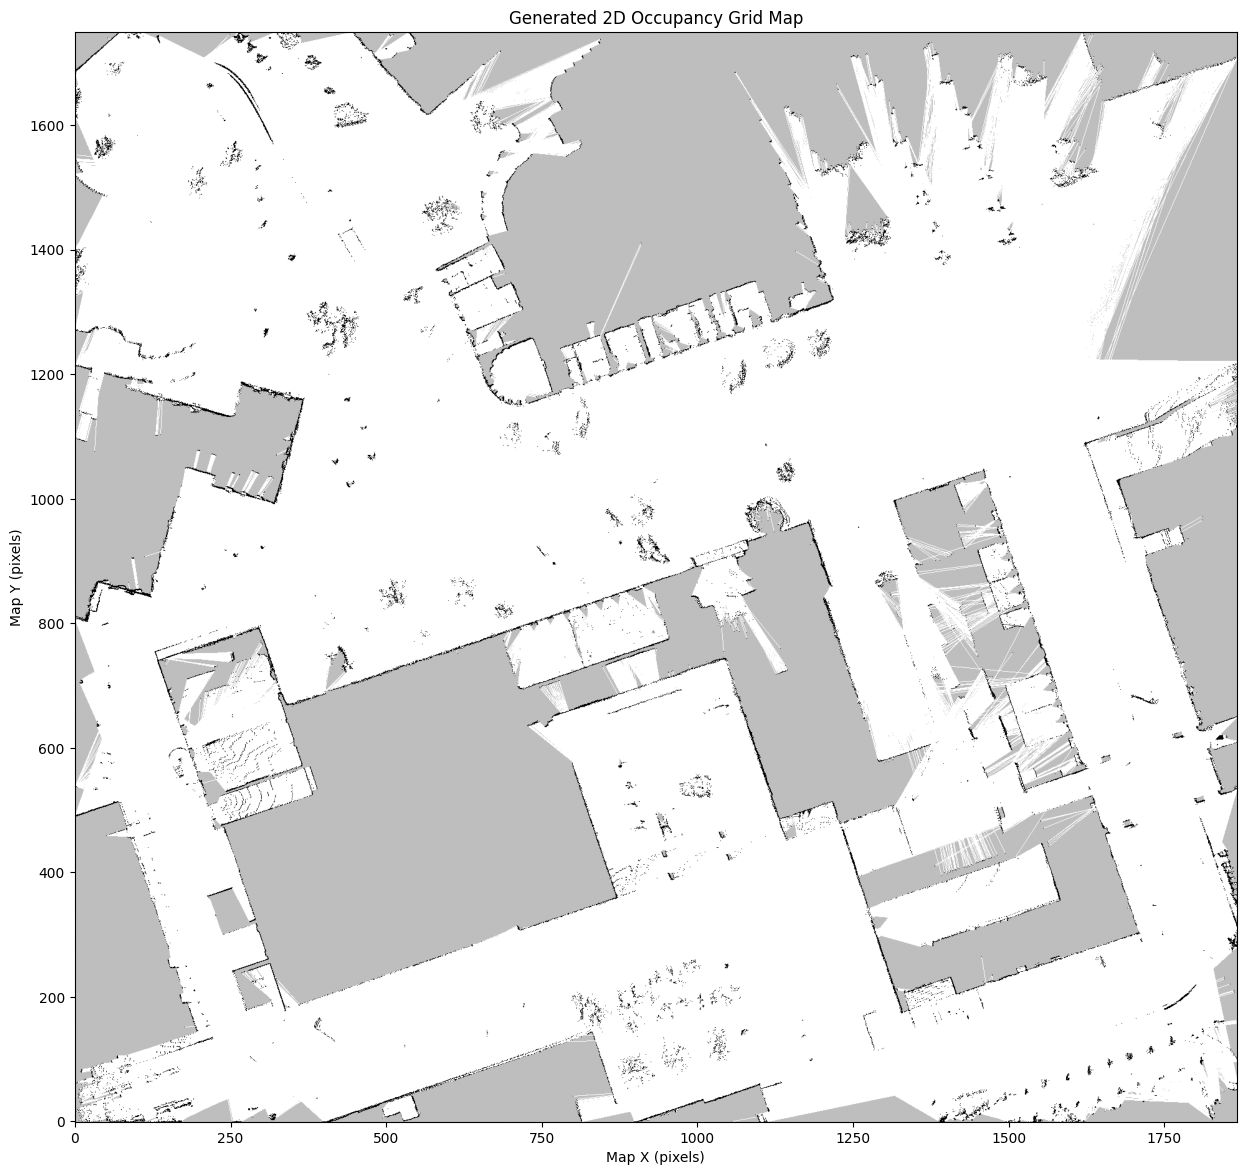

In [ ]:
# === STEP 7: VISUALIZE THE FINAL MAP ===
print("\n--- Step 7: Displaying the final map ---")

def log_odds_to_prob(log_odds_grid):
    return 1.0 - (1.0 / (1.0 + np.exp(log_odds_grid)))

map_for_display = log_odds_to_prob(occupancy_grid)
map_for_display[np.isclose(occupancy_grid, 0.0)] = 0.5

plt.figure(figsize=(15, 15))
plt.imshow(map_for_display, cmap='gray_r', origin='lower')
plt.title("Generated 2D Occupancy Grid Map")
plt.xlabel("Map X (pixels)")
plt.ylabel("Map Y (pixels)")
plt.show()